# 03 - Feature engineering and feature selection

**Goal:** go from the cleaned data (notebook 01) to the 24 model features stored in `data/*_final.csv`,
and show the evidence for choosing them.

Steps:
1. Build engineered features. Each one uses only information **on or before `snapshot_date`**.
2. Check the churn rate of the main new flags (train).
3. Select features on **train only**: correlation filter -> rare-feature filter -> L1 (Lasso) logistic regression
   with time-series cross-validation. Then compare the result with the 24 features in `data/train_final.csv`.
4. Build the final tables with the 24 features and save them as `data/processed/*_rebuilt.csv`
   (the original `data/*_final.csv` files are **not** overwritten).
5. Reproducibility check: compare the rebuilt files with `data/*_final.csv` column by column.
6. A note on scaling.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
RANDOM_SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
TARGET = "churn_next_30d"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titleweight": "bold"})

date_cols = ["snapshot_date", "signup_date", "contract_end_date", "last_login_date",
             "last_bill_due_date", "last_payment_date"]
clean = {name: pd.read_csv(PROCESSED_DIR / f"{name}_clean.csv", parse_dates=date_cols)
         for name in ["train", "validation", "test"]}
{name: d.shape for name, d in clean.items()}

{'train': (665, 34), 'validation': (172, 34), 'test': (183, 34)}

## 1. Build the engineered features

One function builds every feature, so train, validation and test are treated in exactly the same way.
The only value learned from data is the **median charge per plan**, and it comes from **train only**.

| Group | Feature | Business reason |
|---|---|---|
| Tenure | `tenure_days`, `tenure_months` (= days / 30.4), `tenure_band` (0-6m, 7-12m, 13-24m, 25m+) | new customers have not settled in yet |
| Engagement | `days_since_login`, `inactive_flag` (> 30 days) | a customer who stops logging in is drifting away |
| Contract | `days_until_contract_end` (-1 = month-to-month), `contract_end_known`, `renewal_due_60d` (0-60 days) | renewal is a natural moment to leave |
| Payment | `days_since_last_payment` (-1 = unpaid), `days_since_bill_due`, `payment_delay_days`, `bill_unpaid_flag` | late or missing payment signals disengagement or money trouble |
| Usage | `usage_change_m3_to_m1` (m1 - m3), `usage_change_pct_m3_to_m1` = (m1 - m3) / (m3 + 1) x 100, `usage_avg_3m`, `usage_std_3m`, `usage_drop_flag` (< -20%), `consecutive_usage_decline` (m1 < m2 < m3) | falling usage was the strongest signal in EDA |
| Service | `total_tickets_3m`, `open_tickets`, `resolution_rate` (1 if no tickets), `low_csat_flag` (CSAT <= 2), `service_pain_score` = open + 2 x complaints + low CSAT | unresolved problems push customers out |
| Billing | `billing_risk` = late payments + disputes, `unpaid_amount_6m` = billed - paid, `payment_ratio_6m` = paid / billed | billing friction |
| Price | `charge_change_3m`, `charge_change_pct_3m`, `price_hike_flag` (> 1%), `net_charge` = charge - discount, `discount_pct`, `charge_vs_plan_median`, `value_score` | price rises and poor value trigger switching |
| Loyalty | `is_autopay`, `is_month_to_month`, `stickiness` = autopay + add-ons + (not month-to-month), `engagement_score` = logins / (days_since_login + 1) | ties that make leaving harder |
| Interactions | `mtm_x_usage_drop`, `mtm_x_open_ticket`, `price_hike_no_discount`, `new_and_unhappy`, `renewal_due_and_unhappy` | two warning signs together are worse than one |

The "+1" in the usage-change formula avoids dividing by zero for customers with 0 hours three months ago.

In [2]:
def build_features(d, plan_median_charge):
    """Return a copy of the cleaned data with all engineered features added."""
    d = d.copy()
    snap = d["snapshot_date"]

    # --- tenure: how long the customer has been with us at the snapshot
    d["tenure_days"] = (snap - d["signup_date"]).dt.days
    d["tenure_months"] = d["tenure_days"] / 30.4
    d["tenure_band"] = pd.cut(d["tenure_months"], [0, 6, 12, 24, np.inf], right=False,
                              labels=["0-6m", "7-12m", "13-24m", "25m+"]).astype(str)

    # --- engagement
    d["days_since_login"] = (snap - d["last_login_date"]).dt.days
    d["inactive_flag"] = (d["days_since_login"] > 30).astype(int)

    # --- contract (blank end date = month-to-month -> -1)
    d["days_until_contract_end"] = (d["contract_end_date"] - snap).dt.days.fillna(-1).astype(int)
    d["contract_end_known"] = d["contract_end_date"].notna().astype(int)
    d["renewal_due_60d"] = d["days_until_contract_end"].between(0, 60).astype(int)

    # --- payment (blank payment date = last bill unpaid -> -1)
    d["days_since_last_payment"] = (snap - d["last_payment_date"]).dt.days.fillna(-1).astype(int)
    d["days_since_bill_due"] = (snap - d["last_bill_due_date"]).dt.days
    # paid: days between due date and payment (negative = paid early); unpaid: days overdue so far
    d["payment_delay_days"] = (d["last_payment_date"] - d["last_bill_due_date"]).dt.days \
        .fillna(d["days_since_bill_due"]).astype(int)
    d["bill_unpaid_flag"] = d["last_payment_date"].isna().astype(int)

    # --- usage (m1 = last month, m3 = three months ago)
    usage = d[["usage_hours_m1", "usage_hours_m2", "usage_hours_m3"]]
    d["usage_change_m3_to_m1"] = d["usage_hours_m1"] - d["usage_hours_m3"]
    d["usage_change_pct_m3_to_m1"] = d["usage_change_m3_to_m1"] / (d["usage_hours_m3"] + 1) * 100
    d["usage_avg_3m"] = usage.mean(axis=1)
    d["usage_std_3m"] = usage.std(axis=1)
    d["usage_drop_flag"] = (d["usage_change_pct_m3_to_m1"] < -20).astype(int)
    d["consecutive_usage_decline"] = ((d["usage_hours_m1"] < d["usage_hours_m2"]) &
                                      (d["usage_hours_m2"] < d["usage_hours_m3"])).astype(int)

    # --- service
    d["total_tickets_3m"] = d["support_tickets_m1"] + d["support_tickets_m2"] + d["support_tickets_m3"]
    d["open_tickets"] = d["total_tickets_3m"] - d["tickets_resolved_last_90d"]
    d["resolution_rate"] = np.where(d["total_tickets_3m"] > 0,
                                    d["tickets_resolved_last_90d"] / d["total_tickets_3m"].clip(lower=1), 1.0)
    d["low_csat_flag"] = (d["last_csat_score"] <= 2).astype(int)
    d["service_pain_score"] = d["open_tickets"] + 2 * d["complaints_last_90d"] + d["low_csat_flag"]

    # --- billing
    d["billing_risk"] = d["late_payments_last_6m"] + d["billing_disputes_last_6m"]
    d["unpaid_amount_6m"] = d["total_billed_last_6m"] - d["total_paid_last_6m"]
    d["payment_ratio_6m"] = d["total_paid_last_6m"] / d["total_billed_last_6m"]

    # --- price
    d["charge_change_3m"] = d["monthly_charge_current"] - d["monthly_charge_3m_ago"]
    d["charge_change_pct_3m"] = d["charge_change_3m"] / d["monthly_charge_3m_ago"] * 100
    d["price_hike_flag"] = (d["charge_change_pct_3m"] > 1).astype(int)
    d["net_charge"] = d["monthly_charge_current"] - d["discount_amount"]
    d["discount_pct"] = d["discount_amount"] / d["monthly_charge_current"] * 100
    d["charge_vs_plan_median"] = d["monthly_charge_current"] / d["plan_type"].map(plan_median_charge)
    d["value_score"] = d["usage_avg_3m"] / d["net_charge"] * 100      # usage hours per 100 paid

    # --- loyalty / engagement
    d["is_autopay"] = (d["payment_method"] == "Autopay").astype(int)
    d["is_month_to_month"] = (d["contract_type"] == "Month-to-month").astype(int)
    d["stickiness"] = d["is_autopay"] + d["num_addon_services"] + (1 - d["is_month_to_month"])
    d["engagement_score"] = d["app_logins_last_30d"] / (d["days_since_login"] + 1)

    # --- interactions: two warning signs at once
    d["mtm_x_usage_drop"] = d["is_month_to_month"] * d["usage_drop_flag"]
    d["mtm_x_open_ticket"] = d["is_month_to_month"] * (d["open_tickets"] > 0).astype(int)
    d["price_hike_no_discount"] = d["price_hike_flag"] * (d["discount_amount"] == 0).astype(int)
    d["new_and_unhappy"] = ((d["tenure_months"] < 6) & (d["low_csat_flag"] == 1)).astype(int)
    d["renewal_due_and_unhappy"] = d["renewal_due_60d"] * d["low_csat_flag"]
    return d

# the only learned value: median current charge per plan, from TRAIN only
plan_median_charge = clean["train"].groupby("plan_type")["monthly_charge_current"].median()
print("Plan median charge (train):", plan_median_charge.round(2).to_dict())

feat = {name: build_features(d, plan_median_charge) for name, d in clean.items()}
train = feat["train"]

ENGINEERED = ["tenure_days", "tenure_months", "days_since_login", "inactive_flag", "days_until_contract_end",
              "contract_end_known", "renewal_due_60d", "days_since_last_payment", "days_since_bill_due",
              "payment_delay_days", "bill_unpaid_flag", "usage_change_m3_to_m1", "usage_change_pct_m3_to_m1",
              "usage_avg_3m", "usage_std_3m", "usage_drop_flag", "consecutive_usage_decline", "total_tickets_3m",
              "open_tickets", "resolution_rate", "low_csat_flag", "service_pain_score", "billing_risk",
              "unpaid_amount_6m", "payment_ratio_6m", "charge_change_3m", "charge_change_pct_3m", "price_hike_flag",
              "net_charge", "discount_pct", "charge_vs_plan_median", "value_score", "is_autopay",
              "is_month_to_month", "stickiness", "engagement_score", "mtm_x_usage_drop", "mtm_x_open_ticket",
              "price_hike_no_discount", "new_and_unhappy", "renewal_due_and_unhappy"]
print("Engineered numeric features:", len(ENGINEERED), "+ tenure_band (categorical)")
print("Missing values in engineered features:", int(pd.concat(feat.values())[ENGINEERED].isna().sum().sum()))
train[ENGINEERED].describe().T.round(2)

Plan median charge (train): {'Basic': 310.73, 'Family': 1241.38, 'Premium': 944.33, 'Standard': 574.12}
Engineered numeric features: 41 + tenure_band (categorical)
Missing values in engineered features: 0


,count,mean,std,min,25%,50%,75%,max
tenure_days,665.0,823.62,591.84,20.00,389.00,679.00,1093.00,2900.00
tenure_months,665.0,27.09,19.47,0.66,12.80,22.34,35.95,95.39
days_since_login,665.0,12.11,16.60,0.00,2.00,6.00,15.00,105.00
inactive_flag,665.0,0.10,0.31,0.00,0.00,0.00,0.00,1.00
days_until_contract_end,665.0,125.20,183.81,-1.00,-1.00,-1.00,238.00,726.00
contract_end_known,665.0,0.45,0.50,0.00,0.00,0.00,1.00,1.00
renewal_due_60d,665.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
days_since_last_payment,665.0,13.97,7.72,-1.00,8.00,14.00,20.00,29.00
days_since_bill_due,665.0,12.68,7.09,1.00,6.00,13.00,19.00,24.00
payment_delay_days,665.0,-1.32,3.33,-5.00,-4.00,-2.00,0.00,15.00


## 2. Do the new flags separate churners? (train)

,flag,customers_flagged,pct_of_train,churn_rate_flag_1,churn_rate_flag_0
0,mtm_x_usage_drop,109,16.391,0.560,0.162
1,inactive_flag,69,10.376,0.536,0.191
2,usage_drop_flag,207,31.128,0.454,0.124
3,mtm_x_open_ticket,121,18.195,0.421,0.184
4,consecutive_usage_decline,321,48.271,0.349,0.113
5,renewal_due_and_unhappy,3,0.451,0.333,0.227
6,low_csat_flag,103,15.489,0.330,0.208
7,is_month_to_month,370,55.639,0.295,0.142
8,price_hike_flag,305,45.865,0.282,0.181
9,price_hike_no_discount,162,24.361,0.278,0.211


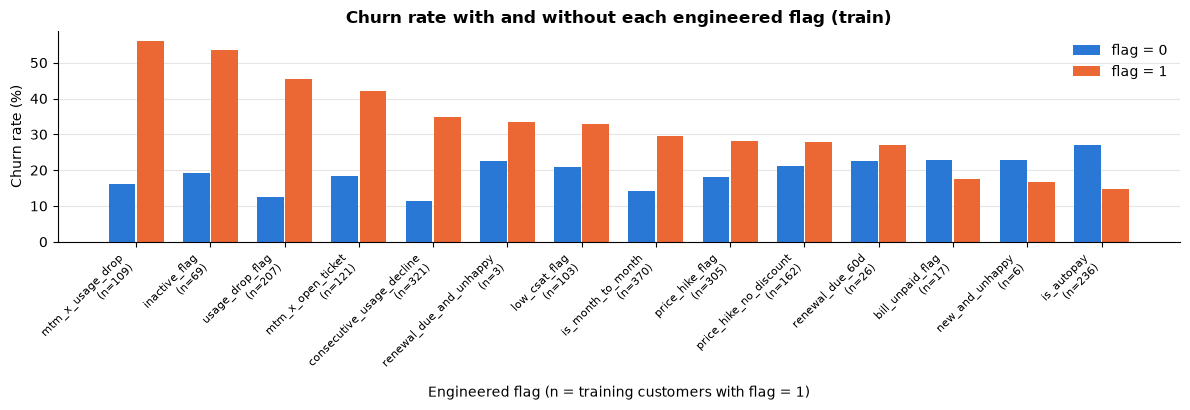

In [3]:
flags = ["usage_drop_flag", "consecutive_usage_decline", "inactive_flag", "low_csat_flag", "renewal_due_60d",
         "price_hike_flag", "bill_unpaid_flag", "is_month_to_month", "is_autopay", "mtm_x_usage_drop",
         "mtm_x_open_ticket", "price_hike_no_discount", "new_and_unhappy", "renewal_due_and_unhappy"]
rows = []
for f in flags:
    on = train[f] == 1
    rows.append({"flag": f, "customers_flagged": int(on.sum()), "pct_of_train": on.mean() * 100,
                 "churn_rate_flag_1": train.loc[on, TARGET].mean(), "churn_rate_flag_0": train.loc[~on, TARGET].mean()})
flag_table = pd.DataFrame(rows).sort_values("churn_rate_flag_1", ascending=False).reset_index(drop=True)
display(flag_table.round(3))

x = np.arange(len(flag_table))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(x - 0.19, flag_table["churn_rate_flag_0"] * 100, 0.36, color=BLUE, label="flag = 0")
ax.bar(x + 0.19, flag_table["churn_rate_flag_1"] * 100, 0.36, color=ORANGE, label="flag = 1")
ax.set_xticks(x, [f"{f}\n(n={n})" for f, n in zip(flag_table["flag"], flag_table["customers_flagged"])],
              rotation=45, ha="right", fontsize=8)
ax.set_title("Churn rate with and without each engineered flag (train)")
ax.set_xlabel("Engineered flag (n = training customers with flag = 1)")
ax.set_ylabel("Churn rate (%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Most flags clearly separate churners: month-to-month with a usage drop, usage drop, inactivity, and
month-to-month with an open ticket all lift churn well above the 22.7% average. `is_autopay` works the other
way (it protects). The two last interactions are flagged for only a handful of customers, so their churn
rates are not reliable. This is why they are removed as rare features in step 3b.

## 3. Feature selection (train only)

**Candidate pool.** All engineered features above, plus raw columns that no engineered feature fully replaces
(tickets per month, complaints, CSAT, add-ons, logins, late payments, disputes, `csat_missing`), plus the
categorical columns. Raw money and usage *levels* (`monthly_charge_current`, `total_billed_last_6m`,
`usage_hours_m1..m3`, ...) are left out because their engineered versions (`net_charge`, change %, averages)
replace them, and EDA showed they are near-copies of each other.

All selection steps use **training rows only**. Validation and test are not looked at here.

In [4]:
RAW_KEEP = ["num_addon_services", "app_logins_last_30d", "support_tickets_m1", "support_tickets_m2",
            "support_tickets_m3", "complaints_last_90d", "last_csat_score", "csat_missing",
            "late_payments_last_6m", "billing_disputes_last_6m"]
CATEGORICAL = ["contract_type", "tenure_band", "region", "paperless_billing", "payment_method",
               "acquisition_channel", "plan_type"]
numeric_pool = RAW_KEEP + ENGINEERED

# TimeSeriesSplit needs the rows in time order
train_sorted = train.sort_values(["snapshot_date", "customer_id"]).reset_index(drop=True)
y_train = train_sorted[TARGET]
print("Candidate pool:", len(numeric_pool), "numeric +", len(CATEGORICAL), "categorical =",
      len(numeric_pool) + len(CATEGORICAL))

Candidate pool: 51 numeric + 7 categorical = 58


### 3a. Remove highly correlated pairs (|r| >= 0.9)

Two features that move together almost perfectly carry the same information. Keeping both makes the
model's coefficients unstable and harder to explain. From each pair we keep the feature that is **more
correlated with churn** on train and drop the other.

In [5]:
corr = train_sorted[numeric_pool].corr().abs()
churn_corr = train_sorted[numeric_pool].corrwith(y_train).abs()

pairs, dropped = [], set()
for i, a in enumerate(numeric_pool):
    for b in numeric_pool[i + 1:]:
        if corr.loc[a, b] >= 0.9:
            pairs.append((a, b, corr.loc[a, b]))

pair_rows = []
for a, b, r in sorted(pairs, key=lambda p: -p[2]):
    if a in dropped or b in dropped:
        decision = "already handled"
    else:
        loser = a if churn_corr[a] < churn_corr[b] else b
        dropped.add(loser)
        decision = f"drop {loser}"
    pair_rows.append({"feature_a": a, "feature_b": b, "abs_corr": round(r, 3),
                      "churn_corr_a": round(churn_corr[a], 3), "churn_corr_b": round(churn_corr[b], 3),
                      "decision": decision})
pair_table = pd.DataFrame(pair_rows)
display(pair_table)
print("Dropped for high correlation:", sorted(dropped))

,feature_a,feature_b,abs_corr,churn_corr_a,churn_corr_b,decision
0,tenure_days,tenure_months,1.000,0.046,0.046,drop tenure_days
1,contract_end_known,is_month_to_month,0.985,0.181,0.181,drop is_month_to_month
2,late_payments_last_6m,billing_risk,0.961,0.245,0.256,drop late_payments_last_6m
3,usage_change_m3_to_m1,usage_change_pct_m3_to_m1,0.937,0.363,0.394,drop usage_change_m3_to_m1


Dropped for high correlation: ['is_month_to_month', 'late_payments_last_6m', 'tenure_days', 'usage_change_m3_to_m1']


### 3b. Remove rare features

A yes/no feature that is "yes" for only a few training customers cannot be learned reliably. Its churn
rate in step 2 rests on a handful of people. Rule: drop binary features with **fewer than 10 positive rows
in train** (about 1.5%).

In [6]:
binary_cols = [c for c in numeric_pool if c not in dropped and set(train_sorted[c].unique()) <= {0, 1}]
positives = train_sorted[binary_cols].sum().sort_values()
rare = positives[positives < 10].index.tolist()
display(positives.head(6).to_frame("positive rows in train"))
print("Dropped as rare:", rare)

numeric_after_filters = [c for c in numeric_pool if c not in dropped and c not in rare]
print("Numeric features left:", len(numeric_after_filters), "| categorical:", len(CATEGORICAL))

,positive rows in train
renewal_due_and_unhappy,3
new_and_unhappy,6
bill_unpaid_flag,17
renewal_due_60d,26
csat_missing,33
inactive_flag,69


Dropped as rare: ['renewal_due_and_unhappy', 'new_and_unhappy']
Numeric features left: 45 | categorical: 7


### 3c. L1 (Lasso) logistic regression with time-series cross-validation

L1 regularisation pushes the coefficients of unhelpful features to exactly zero, so the features with a
non-zero coefficient are the ones the model "keeps".

- Numbers are standardised (`StandardScaler`) and categories one-hot encoded inside the pipeline, so each
  cross-validation fold is fitted on its own training part only.
- `class_weight="balanced"` gives churners more weight, because they are only 22% of the rows.
- `TimeSeriesSplit(4)`: each fold trains on earlier months and validates on the next block of months, the
  same "past -> future" logic as our main split.
- The strength `C` (smaller = fewer features) is chosen by **average precision** (PR-AUC).

In [7]:
def make_l1_pipeline(numeric_cols, categorical_cols, C=1.0):
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])
    model = LogisticRegression(l1_ratio=1, C=C, solver="liblinear", class_weight="balanced",
                               max_iter=5000, random_state=RANDOM_SEED)
    return Pipeline([("pre", pre), ("model", model)])

tscv = TimeSeriesSplit(n_splits=4)
search = GridSearchCV(make_l1_pipeline(numeric_after_filters, CATEGORICAL),
                      {"model__C": [0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3, 1.0]},
                      cv=tscv, scoring="average_precision")
search.fit(train_sorted[numeric_after_filters + CATEGORICAL], y_train)

cv_table = pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
cv_table.columns = ["C", "mean_cv_average_precision", "std"]
display(cv_table.round(3))
print("Best C:", search.best_params_["model__C"], "| CV average precision:", round(search.best_score_, 3))

,C,mean_cv_average_precision,std
0,0.01,0.337,0.122
1,0.02,0.441,0.141
2,0.03,0.547,0.074
3,0.05,0.565,0.058
4,0.10,0.592,0.058
5,0.20,0.590,0.067
6,0.30,0.582,0.085
7,1.00,0.550,0.092


Best C: 0.1 | CV average precision: 0.592


In [8]:
best = search.best_estimator_
coef = pd.Series(best["model"].coef_[0], index=best["pre"].get_feature_names_out())

def original_name(encoded):
    """Map 'num__x' -> 'x' and 'cat__contract_type_One year' -> 'contract_type'."""
    kind, name = encoded.split("__", 1)
    if kind == "cat":
        return next(c for c in CATEGORICAL if name.startswith(c + "_"))
    return name

coef_table = coef.rename("coef").to_frame()
coef_table["feature"] = [original_name(i) for i in coef.index]
importance = coef_table.groupby("feature")["coef"].apply(lambda s: s.abs().max()).sort_values(ascending=False)
selected = importance[importance > 0].index.tolist()
removed_by_l1 = importance[importance == 0].index.tolist()

print(f"L1 kept {len(selected)} features:")
display(importance[importance > 0].round(4).to_frame("largest |coefficient| (standardised)"))
print("Set to zero by L1:", removed_by_l1)

L1 kept 25 features:


,largest |coefficient| (standardised)
feature,
usage_change_pct_m3_to_m1,0.7612
contract_type,0.4338
billing_risk,0.4279
contract_end_known,0.3587
service_pain_score,0.2667
unpaid_amount_6m,0.2367
inactive_flag,0.2322
stickiness,0.2018
paperless_billing,0.1790


Set to zero by L1: ['csat_missing', 'days_until_contract_end', 'complaints_last_90d', 'app_logins_last_30d', 'acquisition_channel', 'days_since_last_payment', 'days_since_login', 'charge_vs_plan_median', 'charge_change_pct_3m', 'consecutive_usage_decline', 'mtm_x_usage_drop', 'price_hike_no_discount', 'plan_type', 'payment_method', 'payment_ratio_6m', 'payment_delay_days', 'net_charge', 'num_addon_services', 'open_tickets', 'mtm_x_open_ticket', 'low_csat_flag', 'is_autopay', 'support_tickets_m2', 'usage_avg_3m', 'total_tickets_3m', 'usage_std_3m', 'value_score']


### 3d. Compare with the 24 features in `data/train_final.csv`

In [9]:
final_cols = pd.read_csv(ROOT / "data" / "train_final.csv", nrows=1).columns.tolist()
FINAL_24 = [c for c in final_cols if c not in ("customer_id", "snapshot_date", TARGET)]

in_both = sorted(set(selected) & set(FINAL_24))
only_ours = sorted(set(selected) - set(FINAL_24))
only_final = sorted(set(FINAL_24) - set(selected))
print(f"Final 24 features re-selected here: {len(in_both)} of 24")
print("In both:", in_both)
print("Selected here but not in the final 24:", only_ours)
print("In the final 24 but not selected here:", only_final)

Final 24 features re-selected here: 19 of 24
In both: ['bill_unpaid_flag', 'billing_disputes_last_6m', 'billing_risk', 'contract_type', 'discount_pct', 'inactive_flag', 'last_csat_score', 'paperless_billing', 'price_hike_flag', 'region', 'renewal_due_60d', 'resolution_rate', 'service_pain_score', 'stickiness', 'support_tickets_m1', 'support_tickets_m3', 'tenure_band', 'unpaid_amount_6m', 'usage_change_pct_m3_to_m1']
Selected here but not in the final 24: ['charge_change_3m', 'contract_end_known', 'days_since_bill_due', 'engagement_score', 'tenure_months', 'usage_drop_flag']
In the final 24 but not selected here: ['acquisition_channel', 'charge_change_pct_3m', 'days_since_login', 'net_charge', 'payment_method']


In [10]:
# For each final feature we did not select: what happened to it, and which selected feature is most similar?
num_like = [c for c in numeric_pool]
explain_rows = []
for f in only_final:
    if f in CATEGORICAL:
        reason = "set to zero by L1" if f in removed_by_l1 else "-"
        explain_rows.append({"final_feature": f, "what_happened": reason, "closest_selected_feature": "-",
                             "abs_corr": np.nan})
        continue
    if f in dropped:
        reason = "dropped in correlation filter"
    elif f in rare:
        reason = "dropped as rare"
    else:
        reason = "set to zero by L1"
    sims = train_sorted[[c for c in selected if c in num_like]].corrwith(train_sorted[f]).abs()
    explain_rows.append({"final_feature": f, "what_happened": reason,
                         "closest_selected_feature": sims.idxmax(), "abs_corr": round(sims.max(), 3)})
pd.DataFrame(explain_rows)

,final_feature,what_happened,closest_selected_feature,abs_corr
0,acquisition_channel,set to zero by L1,-,NaN
1,charge_change_pct_3m,set to zero by L1,price_hike_flag,0.875
2,days_since_login,set to zero by L1,inactive_flag,0.826
3,net_charge,set to zero by L1,discount_pct,0.436
4,payment_method,set to zero by L1,-,NaN


In [11]:
# Does the choice matter? Same L1 model, same folds, same C: our selection vs the final 24
X_cols_ours = selected
def cv_ap(cols):
    num = [c for c in cols if c not in CATEGORICAL]
    cat = [c for c in cols if c in CATEGORICAL]
    pipe = make_l1_pipeline(num, cat, C=search.best_params_["model__C"])
    scores = cross_val_score(pipe, train_sorted[cols], y_train, cv=tscv, scoring="average_precision")
    return scores.mean(), scores.std()

compare = pd.DataFrame({
    "feature_set": ["selected in this notebook", "final 24 (data/*_final.csv)"],
    "n_features": [len(selected), len(FINAL_24)],
    "cv_average_precision": [cv_ap(selected)[0], cv_ap(FINAL_24)[0]],
    "cv_std": [cv_ap(selected)[1], cv_ap(FINAL_24)[1]],
})
compare.round(3)

,feature_set,n_features,cv_average_precision,cv_std
0,selected in this notebook,25,0.595,0.059
1,final 24 (data/*_final.csv),24,0.594,0.053


**What the comparison shows (honest summary):**

- Our selection on train keeps **19 of the 24** final features, including all the strongest signals:
  usage change %, contract type, billing risk, service pain, unpaid amount, inactivity and stickiness.
- The 5 final features we did not pick mostly have a **near-twin** in our set. L1 tends to keep one feature of a
  correlated group and set the rest to zero:
  - `charge_change_pct_3m` -> we kept `charge_change_3m` (same idea in money instead of %) and `price_hike_flag` (r = 0.88)
  - `days_since_login` -> we kept `inactive_flag` (r = 0.83) and `engagement_score`
  - `net_charge` -> we kept `discount_pct`
  - `payment_method` -> its main signal (autopay or not) is already inside `stickiness`
  - `acquisition_channel` -> weak in EDA (churn 20-26% across channels)
- The 6 extra features we picked (`contract_end_known`, `tenure_months`, `usage_drop_flag`, `charge_change_3m`,
  `engagement_score`, `days_since_bill_due`) are mostly near-twins of final features too, and several have very
  small coefficients.
- **Why the lists differ:** the original selection started from a smaller pool (29 features, see README) and we
  started from 58. With 665 training rows, L1 is sensitive to which correlated features are in the pool.
- **Does it matter?** With the same model, folds and `C`, both sets reach the same cross-validated average precision
  (0.595 vs 0.594, std about 0.06), so the data cannot tell them apart. We therefore keep the **24 features already
  used by the trained model in `src/`**. They were fixed on train before validation and test were used, and
  re-selecting now would change a model that has already been evaluated.

## 4. Build the final train / validation / test tables

The model in `src/` was trained on the 24 features in `data/*_final.csv`, so we rebuild exactly those
columns, in the same order, from our cleaned data and engineered features.

In [12]:
rebuilt = {}
for name, d in feat.items():
    table = d[final_cols].sort_values(["snapshot_date", "customer_id"]).copy()
    table["snapshot_date"] = table["snapshot_date"].dt.strftime("%Y-%m-%d")
    table.to_csv(PROCESSED_DIR / f"{name}_rebuilt.csv", index=False)
    rebuilt[name] = table
    print(f"data/processed/{name}_rebuilt.csv: {table.shape[0]} rows x {table.shape[1]} columns, "
          f"missing values = {int(table.isna().sum().sum())}")
rebuilt["train"].head()

data/processed/train_rebuilt.csv: 665 rows x 27 columns, missing values = 0
data/processed/validation_rebuilt.csv: 172 rows x 27 columns, missing values = 0
data/processed/test_rebuilt.csv: 183 rows x 27 columns, missing values = 0


,customer_id,snapshot_date,usage_change_pct_m3_to_m1,billing_risk,contract_type,service_pain_score,inactive_flag,unpaid_amount_6m,stickiness,price_hike_flag,discount_pct,tenure_band,region,paperless_billing,resolution_rate,days_since_login,payment_method,bill_unpaid_flag,billing_disputes_last_6m,charge_change_pct_3m,renewal_due_60d,support_tickets_m1,acquisition_channel,net_charge,support_tickets_m3,last_csat_score,churn_next_30d
0,CUST200002,2025-01-31,-22.370618,0,Two year,2,1,0.00,4,0,0.000000,7-12m,West,Yes,1.0,33,Autopay,0,0,0.000000,0,1,Online,321.37,0,5.0,1
1,CUST200003,2025-01-31,11.458333,0,One year,1,0,0.00,2,0,4.304259,7-12m,South,No,0.5,4,Credit card,0,0,0.000000,1,1,Online,1111.64,1,3.0,0
2,CUST200024,2025-01-31,-46.486486,4,Month-to-month,0,0,0.00,2,1,15.809277,25m+,East,Yes,1.0,20,UPI,0,1,9.999304,0,0,Retail store,532.54,0,5.0,1
3,CUST200025,2025-01-31,-5.934718,1,Month-to-month,1,0,0.00,0,0,19.568323,25m+,East,Yes,1.0,4,UPI,0,1,0.000000,0,0,Online,411.03,0,1.0,0
4,CUST200033,2025-01-31,17.592593,2,Month-to-month,4,0,931.31,2,0,0.000000,0-6m,North,Yes,0.5,5,UPI,0,0,0.000000,0,1,Call center,514.46,0,1.0,0


## 5. Reproducibility check: rebuilt vs `data/*_final.csv`

For each split we join the two files on `customer_id` + `snapshot_date` and compare every column.
Numbers count as matching when they agree to within 1e-6, and text must match exactly.
We report what we find, and nothing is adjusted to force a match.

In [13]:
def compare_files(rebuilt_df, final_df):
    merged = final_df.merge(rebuilt_df, on=["customer_id", "snapshot_date"], how="outer",
                            suffixes=("_final", "_rebuilt"), indicator=True)
    both = merged[merged["_merge"] == "both"]
    rows = []
    for col in FINAL_24 + [TARGET]:
        a, b = both[f"{col}_final"], both[f"{col}_rebuilt"]
        if pd.api.types.is_numeric_dtype(a):
            match = np.isclose(a, b, rtol=0, atol=1e-6)
            max_diff = float(np.abs(a - b).max())
        else:
            match = (a == b).to_numpy()
            max_diff = np.nan
        rows.append({"column": col, "match_pct": match.mean() * 100,
                     "rows_different": int((~match).sum()), "max_abs_diff": max_diff})
    return merged, pd.DataFrame(rows)

results, merged_all = {}, {}
for name in ["train", "validation", "test"]:
    final_df = pd.read_csv(ROOT / "data" / f"{name}_final.csv")
    merged, table = compare_files(rebuilt[name], final_df)
    merged_all[name] = merged
    print(f"{name:10s} rows final={len(final_df)}, rebuilt={len(rebuilt[name])}, "
          f"matched on id+date={int((merged['_merge'] == 'both').sum())}")
    results[name] = table.set_index("column")

summary = pd.concat({n: t["match_pct"] for n, t in results.items()}, axis=1)
summary["rows_different_total"] = sum(t["rows_different"] for t in results.values())
summary["max_abs_diff"] = pd.concat([t["max_abs_diff"] for t in results.values()], axis=1).max(axis=1)
summary.round(3)

train      rows final=665, rebuilt=665, matched on id+date=665
validation rows final=172, rebuilt=172, matched on id+date=172
test       rows final=183, rebuilt=183, matched on id+date=183


,train,validation,test,rows_different_total,max_abs_diff
column,,,,,
usage_change_pct_m3_to_m1,100.0,99.419,97.814,5,23.394
billing_risk,100.0,100.000,100.000,0,0.000
contract_type,100.0,100.000,100.000,0,NaN
service_pain_score,100.0,100.000,100.000,0,0.000
inactive_flag,100.0,100.000,100.000,0,0.000
unpaid_amount_6m,100.0,100.000,100.000,0,0.000
stickiness,100.0,100.000,100.000,0,0.000
price_hike_flag,100.0,100.000,100.000,0,0.000
discount_pct,100.0,100.000,100.000,0,0.000


In [14]:
all_rows = sum(len(r) for r in rebuilt.values())
cells_total = all_rows * len(FINAL_24)
cells_diff = int(summary["rows_different_total"].sum())
print(f"Features matching 100% in every split: {(summary['rows_different_total'] == 0).sum()} of {len(FINAL_24) + 1} "
      f"(24 features + target)")
print(f"Feature cells matching overall: {(1 - cells_diff / cells_total) * 100:.2f}% "
      f"({cells_total - cells_diff} of {cells_total})")

Features matching 100% in every split: 24 of 25 (24 features + target)
Feature cells matching overall: 99.98% (24475 of 24480)


In [15]:
# Which rows differ, and why?
diff_rows = []
for name, merged in merged_all.items():
    m = merged[merged["_merge"] == "both"]
    bad = ~np.isclose(m["usage_change_pct_m3_to_m1_final"], m["usage_change_pct_m3_to_m1_rebuilt"], rtol=0, atol=1e-6)
    for _, r in m[bad].iterrows():
        diff_rows.append({"split": name, "customer_id": r["customer_id"],
                          "final_value": r["usage_change_pct_m3_to_m1_final"],
                          "rebuilt_value": r["usage_change_pct_m3_to_m1_rebuilt"]})
diff = pd.DataFrame(diff_rows)

# Compare with the raw file: these customers had a NEGATIVE usage_hours_m1
raw = pd.read_csv(ROOT / "data" / "raw" / "customer_churn_raw_1050.csv").drop_duplicates()
diff = diff.merge(raw[["customer_id", "usage_hours_m1", "usage_hours_m2", "usage_hours_m3"]], on="customer_id")
diff = diff.rename(columns={"usage_hours_m1": "raw_m1", "usage_hours_m2": "raw_m2", "usage_hours_m3": "raw_m3"})

# What usage_m1 would reproduce the final value?  m1 = pct/100 * (m3 + 1) + m3
diff["m1_implied_by_final"] = (diff["final_value"] / 100 * (diff["raw_m3"] + 1) + diff["raw_m3"]).round(2)
diff["m1_used_here_abs"] = diff["raw_m1"].abs()
diff["final_used_raw_m2"] = np.isclose(diff["m1_implied_by_final"], diff["raw_m2"], atol=0.01)
display(diff.round(3))
print("Rows that differ:", len(diff), "| all had negative raw usage_hours_m1:", bool((diff["raw_m1"] < 0).all()),
      "| final value = m1 replaced by raw m2 in every case:", bool(diff["final_used_raw_m2"].all()))
print("Customers with negative raw usage_hours_m1 in the whole file:", int((raw["usage_hours_m1"] < 0).sum()))

# The 20 rows with MISSING raw usage_hours_m3 do match: the original also filled m3 from m2
m3_missing_ids = raw.loc[raw["usage_hours_m3"].isna(), "customer_id"]
print("Rows with missing raw usage_hours_m3:", len(m3_missing_ids),
      "| of these, rows that differ:", int(diff["customer_id"].isin(m3_missing_ids).sum()))

,split,customer_id,final_value,rebuilt_value,raw_m1,raw_m2,raw_m3,m1_implied_by_final,m1_used_here_abs,final_used_raw_m2
0,validation,CUST200362,0.000,6.550,-47.8,44.8,44.8,44.8,47.8,True
1,test,CUST200159,12.458,16.835,-33.7,32.4,28.7,32.4,33.7,True
2,test,CUST200345,-27.982,-51.376,-9.6,14.7,20.8,14.7,9.6,True
3,test,CUST200370,-14.329,-21.951,-24.6,27.1,31.8,27.1,24.6,True
4,test,CUST200440,-0.798,-1.064,-36.2,36.3,36.6,36.3,36.2,True


Rows that differ: 5 | all had negative raw usage_hours_m1: True | final value = m1 replaced by raw m2 in every case: True
Customers with negative raw usage_hours_m1 in the whole file: 5
Rows with missing raw usage_hours_m3: 20 | of these, rows that differ: 0


**Reproducibility result:**

- All 1,020 customers are present in both versions (665 / 172 / 183), and the target matches 100%.
- **23 of the 24 features match 100% in every split**, including all categories, flags, billing, price and service
  features, `days_since_login`, `tenure_band` and the CSAT fill value (train median 4.0).
- Overall, **99.98% of feature cells match** (24,475 of 24,480).
- The only differences are **5 values of `usage_change_pct_m3_to_m1`** (1 validation and 4 test rows, **0 train rows**;
  max difference 23.4 percentage points).

**Why those 5 differ:** they are exactly the 5 customers whose raw `usage_hours_m1` was negative. Our cleaning rule
(notebook 01) takes the absolute value. Working backwards from the final values shows the original pipeline instead
treated these as invalid and **replaced m1 with m2** (the nearest month). Both choices are defensible. We keep our
documented rule and do **not** change the numbers to force a match. No training row is affected, so feature selection
and model training are unchanged. Only 5 scored rows in validation/test would get slightly different inputs.

The check also settles an open question from the README: the 20 rows with a **missing** raw `usage_hours_m3` match
exactly with the rule "m3 <- m2", so that is how the original files were imputed.

## 6. Note on scaling and encoding

We do **not** scale or one-hot encode the saved feature files. They keep readable values (days, %, money,
category names), which the API and dashboard need. Scaling happens inside the model pipeline in `src/`:

- **Logistic Regression** (`src/preprocessing.py`, `make_linear_preprocessor`): median imputation +
  `StandardScaler` for numeric features and `OneHotEncoder(handle_unknown="ignore")` for categorical ones. The
  pipeline is fitted on **train only**, so validation and test statistics never leak into the scaler.
- **CatBoost** splits trees on raw values and handles categories itself, so it needs no scaling or one-hot
  encoding.